# Riemannian Baselines for Cross-Subject Motor-Imagery Decoding

## 1. Objective
This module asks a representation question rather than an architecture question:

> Do covariance-based Riemannian methods provide competitive cross-subject motor-imagery decoding compared with compact convolutional (EEGNet) and attention-based (AttentionBaseNet) networks under matched participant splits?

The neural networks learn features directly from the time series. The Riemannian pipelines instead summarise every trial by its **spatial covariance matrix** (channels x channels), a symmetric positive-definite (SPD) matrix, and classify it with geometry-aware methods implemented in [pyRiemann](https://pyriemann.readthedocs.io).

## 2. Protocol (identical to `9_1_attention_based_loso`)
- BCI Competition IV-2a, 9 subjects, 4 classes (left hand, right hand, foot, tongue), 1-40 Hz cleaned data, window 0.5-3.5 s.
- 9 LOSO folds. In each fold: one test subject, one distinct validation subject (`(i+1) % 9`), seven training subjects.
- No epoch from the test subject is used for fitting, covariance reference estimation, or model selection.
- The hyper-parameters are fixed a priori (no tuning), so the validation subject is **not used for fitting**. Its score is still stored, so any selection between variants can be made on validation only.

## 3. Conditions (2 x 2)
| Model | Normalization | What it isolates |
|---|---|---|
| `MDM` | `none` | Covariances that keep channel variance information |
| `MDM` | `zscore` | Covariances of per-trial, per-channel standardized signals |
| `TangentSpace_LogReg` | `none` | Main Riemannian baseline |
| `TangentSpace_LogReg` | `zscore` | Effect of standardization with the same classifier |

`none` means *filtered and cleaned, only converted from V to µV with a single global factor*. It is not raw data. `zscore` is the transformation used by the neural notebooks. Z-scoring each channel of each trial to unit variance removes variance differences between channels and trials, so the resulting covariance is essentially a correlation matrix. Whether this helps or hurts is an empirical question, hence the ablation.

No augmentation is used here, so that the normalization effect is isolated.

## Setup, path check and constants

In [1]:
%pip install -q pyriemann

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne

from scipy.stats import wilcoxon
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

import pyriemann
from pyriemann.estimation import Covariances
from pyriemann.tangentspace import TangentSpace
from pyriemann.classification import MDM

print(f"pyRiemann {pyriemann.__version__} | MNE {mne.__version__}")

# 1. Reproducibility (the pipelines are deterministic; kept for consistency)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# 2. Directories
os.makedirs('saved_plots', exist_ok=True)

CLEAN_DATA_DIR = os.path.join('.', 'cleaned_data_1_40')
EVENT_ID = {'left': 1, 'right': 2, 'foot': 3, 'tongue': 4}
CLASS_NAMES = ['Left Hand', 'Right Hand', 'Foot', 'Tongue']
LABELS = [0, 1, 2, 3]
T_MIN, T_MAX = 0.5, 3.5
ALL_SUBJECTS = [f'A{i:02d}T' for i in range(1, 10)]
NORMALIZATIONS = ['none', 'zscore']
RESULTS_CSV = 'riemannian_loso_results.csv'   # distinct name: the neural notebooks already use loso_results.csv

# 3. Path verification
print("Checking file paths...")
missing = [
    os.path.join(CLEAN_DATA_DIR, f"{sub}_clean_1_40_raw.fif")
    for sub in ALL_SUBJECTS
    if not os.path.exists(os.path.join(CLEAN_DATA_DIR, f"{sub}_clean_1_40_raw.fif"))
]
assert not missing, f"Missing data files: {missing}"
print("All files found.")

pyRiemann 0.12 | MNE 1.12.0
Checking file paths...
All files found.


## Data loading with explicit normalization
Each `.fif` file is read once. The epochs are converted to µV (single global factor, as in the official pyRiemann motor-imagery examples) and two variants are stored:
- `none`: epochs in µV, no further scaling.
- `zscore`: per-trial, per-channel Z-score, identical to the neural notebooks (Z-scoring is scale invariant, so the V to µV conversion does not change it).

Arrays are `trials x channels x samples`, without the trailing Keras dimension, which is the layout pyRiemann expects.

In [3]:
def load_subject(subject_id):
    '''Loads one cleaned .fif file and returns epochs in microvolts (trials x channels x samples).'''
    file_path = os.path.join(CLEAN_DATA_DIR, f'{subject_id}_clean_1_40_raw.fif')
    raw = mne.io.read_raw_fif(file_path, preload=True, verbose=False)
    raw.pick(['eeg'])
    events, _ = mne.events_from_annotations(raw, event_id=EVENT_ID, verbose=False)
    epochs = mne.Epochs(raw, events, event_id=EVENT_ID, tmin=T_MIN, tmax=T_MAX,
                        baseline=None, preload=True, verbose=False)

    X = epochs.get_data(copy=True).astype(np.float64) * 1e6   # V -> µV
    y = (epochs.events[:, -1] - 1).astype(np.int64)
    return X, y


def apply_normalization(X, mode):
    ''''none': unchanged. 'zscore': per-trial, per-channel standardization (as in the neural notebooks).'''
    if mode == 'none':
        return X
    if mode == 'zscore':
        mean = X.mean(axis=-1, keepdims=True)
        std = X.std(axis=-1, keepdims=True)
        return (X - mean) / (std + 1e-8)
    raise ValueError("normalization must be 'none' or 'zscore'")


data = {mode: {} for mode in NORMALIZATIONS}
print("Loading all subjects into memory...")
for sub in ALL_SUBJECTS:
    X_uv, y_sub = load_subject(sub)
    for mode in NORMALIZATIONS:
        data[mode][sub] = (apply_normalization(X_uv, mode), y_sub)
    del X_uv
print("Loading complete.")

N_CHANS, N_TIMES = data['none'][ALL_SUBJECTS[0]][0].shape[1:]
print(f"Input shape per trial: {N_CHANS} channels x {N_TIMES} samples")


def stack(subjects, normalization):
    '''Concatenates trials of the given subjects for one normalization variant.'''
    X = np.concatenate([data[normalization][s][0] for s in subjects], axis=0)
    y = np.concatenate([data[normalization][s][1] for s in subjects], axis=0)
    return X, y

Loading all subjects into memory...
Loading complete.
Input shape per trial: 22 channels x 751 samples


## Sanity checks
Before any fitting we verify (i) that the label distribution is the expected balanced one, (ii) that the two variants really differ in channel variance, and (iii) the numerical rank of the covariance matrices. A rank below the number of channels (e.g. after ICA or re-referencing) would make plain covariances singular, which is why the pipelines use Ledoit-Wolf shrinkage.

In [4]:
# (i) Trials and class counts per subject
counts = pd.DataFrame({
    sub: np.bincount(data['none'][sub][1], minlength=4) for sub in ALL_SUBJECTS
}, index=CLASS_NAMES).T
counts['Total'] = counts.sum(axis=1)
display(counts)

# (ii) The 'none' variant must keep variance differences between channels, the 'zscore' variant must not
for mode in NORMALIZATIONS:
    X_s = data[mode][ALL_SUBJECTS[0]][0]
    ch_var = X_s.var(axis=-1)                       # trials x channels
    print(f"[{mode:6s}] channel variance: min={ch_var.min():.4g}  median={np.median(ch_var):.4g}  max={ch_var.max():.4g}")
assert data['zscore'][ALL_SUBJECTS[0]][0].var(axis=-1).std() < 1e-3, "zscore variant should have ~unit variance"
assert data['none'][ALL_SUBJECTS[0]][0].var(axis=-1).std() > 1e-3, "'none' variant looks standardized: check the .fif files"

# (iii) Numerical rank of the sample covariances (first 20 trials of the first subject)
X_chk = data['none'][ALL_SUBJECTS[0]][0][:20]
ranks = [np.linalg.matrix_rank(np.cov(trial)) for trial in X_chk]
print(f"Covariance rank on sample trials: min={min(ranks)}, max={max(ranks)} (n_channels={N_CHANS})")

,Left Hand,Right Hand,Foot,Tongue,Total
A01T,72,72,72,72,288
A02T,72,72,72,72,288
A03T,72,72,72,72,288
A04T,72,72,72,72,288
A05T,72,72,72,72,288
A06T,72,72,72,72,288
A07T,72,72,72,72,288
A08T,72,72,72,72,288
A09T,72,72,72,72,288


[none  ] channel variance: min=16.33  median=58.33  max=1149
[zscore] channel variance: min=1  median=1  max=1
Covariance rank on sample trials: min=19, max=19 (n_channels=22)


## Riemannian pipelines
Both pipelines start with Ledoit-Wolf-regularized covariance matrices (`estimator="lwf"`).

- **MDM** (Minimum Distance to Mean): one Riemannian mean per class is estimated on the training trials, and a test trial is assigned to the class whose mean is closest in the Riemannian metric.
- **Tangent space + logistic regression**: covariances are projected onto the tangent space at the Riemannian mean of the **training** covariances (about 253 features for 22 channels), then classified with a linear model.

`tsupdate=False` keeps the tangent-space reference fixed after `fit`, i.e. it is **not** re-estimated on test data. No transductive adaptation is used, which keeps the comparison with the neural networks strictly cross-subject. Hyper-parameters (`C=1.0`) are fixed a priori, not tuned on the test subjects.

In [5]:
def build_models():
    '''Fresh, unfitted pipelines for every fold.'''
    return {
        "MDM": make_pipeline(
            Covariances(estimator="lwf"),
            MDM(metric="riemann"),
        ),
        "TangentSpace_LogReg": make_pipeline(
            Covariances(estimator="lwf"),
            TangentSpace(metric="riemann", tsupdate=False),
            LogisticRegression(C=1.0, max_iter=2000),
        ),
    }

print(list(build_models().keys()))

['MDM', 'TangentSpace_LogReg']


## LOSO loop
Same folds as the neural notebooks. Each pipeline is fitted on the seven training subjects only. Both the validation subject (for variant selection, if needed) and the test subject are predicted after the fit.

In [6]:
def fold_metrics(y_true, y_pred):
    report = classification_report(y_true, y_pred, labels=LABELS, target_names=CLASS_NAMES,
                                   output_dict=True, zero_division=0)
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Macro Precision": report['macro avg']['precision'],
        "Macro Recall": report['macro avg']['recall'],
        "Macro F1": report['macro avg']['f1-score'],
        "Weighted Precision": report['weighted avg']['precision'],
        "Weighted Recall": report['weighted avg']['recall'],
        "Weighted F1": report['weighted avg']['f1-score'],
    }


loso_results = []
pooled = {}   # (model, normalization) -> (targets, predictions) pooled over test folds

print("Starting LOSO evaluation of the Riemannian baselines...\n")
for i, test_sub in enumerate(ALL_SUBJECTS):
    val_sub = ALL_SUBJECTS[(i + 1) % len(ALL_SUBJECTS)]
    train_subs = [s for s in ALL_SUBJECTS if s not in (test_sub, val_sub)]
    assert len(set(train_subs) & {test_sub, val_sub}) == 0 and test_sub != val_sub

    print(f"Fold {i+1}/9 | Test: {test_sub} | Validation: {val_sub} | Train: {train_subs}")

    for norm in NORMALIZATIONS:
        X_tr, y_tr = stack(train_subs, norm)
        X_va, y_va = stack([val_sub], norm)
        X_te, y_te = stack([test_sub], norm)

        for model_name, model in build_models().items():
            t0 = time.time()
            model.fit(X_tr, y_tr)
            fit_time = time.time() - t0

            y_pred_val = model.predict(X_va)
            y_pred_te = model.predict(X_te)

            row = {
                "Test Subject": test_sub,
                "Validation Subject": val_sub,
                "Model": model_name,
                "Normalization": norm,
                **fold_metrics(y_te, y_pred_te),
                "Val Balanced Accuracy": balanced_accuracy_score(y_va, y_pred_val),
                "Fit Time (s)": round(fit_time, 2),
            }
            loso_results.append(row)

            tg, pr = pooled.setdefault((model_name, norm), ([], []))
            tg.extend(y_te.tolist())
            pr.extend(y_pred_te.tolist())

            print(f"   {model_name:20s} {norm:6s} | test bal.acc = {row['Balanced Accuracy']:.3f} "
                  f"| val bal.acc = {row['Val Balanced Accuracy']:.3f} | {fit_time:.1f}s")

results_df = pd.DataFrame(loso_results)
results_df.to_csv(RESULTS_CSV, index=False)
print(f"\nLOSO evaluation finished. Detailed results saved to '{RESULTS_CSV}'.")

Starting LOSO evaluation of the Riemannian baselines...

Fold 1/9 | Test: A01T | Validation: A02T | Train: ['A03T', 'A04T', 'A05T', 'A06T', 'A07T', 'A08T', 'A09T']
   MDM                  none   | test bal.acc = 0.253 | val bal.acc = 0.250 | 4.9s
   TangentSpace_LogReg  none   | test bal.acc = 0.253 | val bal.acc = 0.278 | 5.1s
   MDM                  zscore | test bal.acc = 0.299 | val bal.acc = 0.257 | 4.9s
   TangentSpace_LogReg  zscore | test bal.acc = 0.257 | val bal.acc = 0.257 | 5.2s
Fold 2/9 | Test: A02T | Validation: A03T | Train: ['A01T', 'A04T', 'A05T', 'A06T', 'A07T', 'A08T', 'A09T']
   MDM                  none   | test bal.acc = 0.253 | val bal.acc = 0.330 | 4.7s
   TangentSpace_LogReg  none   | test bal.acc = 0.253 | val bal.acc = 0.281 | 5.0s
   MDM                  zscore | test bal.acc = 0.264 | val bal.acc = 0.316 | 5.0s
   TangentSpace_LogReg  zscore | test bal.acc = 0.260 | val bal.acc = 0.299 | 5.0s
Fold 3/9 | Test: A03T | Validation: A04T | Train: ['A01T', 'A02T'

## Aggregate analysis
As in the neural notebooks, conclusions are drawn from **mean ± standard deviation across the 9 held-out subjects**, not from pooled accuracy. Chance level for 4 balanced classes is 0.25.

In [7]:
results_df = pd.read_csv(RESULTS_CSV)

summary = (results_df
           .groupby(["Model", "Normalization"])[["Accuracy", "Balanced Accuracy", "Macro F1", "Val Balanced Accuracy"]]
           .agg(["mean", "std"])
           .round(3))
print("=== Cross-Subject Robustness (Mean ± Std across 9 test folds) ===")
display(summary)

print("\n=== Per-subject balanced accuracy (test) ===")
per_subject = results_df.pivot_table(index="Test Subject", columns=["Model", "Normalization"],
                                     values="Balanced Accuracy")
display(per_subject.round(3))

=== Cross-Subject Robustness (Mean ± Std across 9 test folds) ===


Accuracy        Balanced Accuracy         \
                                      mean    std              mean    std   
Model               Normalization                                            
MDM                 none             0.263  0.029             0.263  0.029   
                    zscore           0.271  0.024             0.271  0.024   
TangentSpace_LogReg none             0.267  0.024             0.267  0.024   
                    zscore           0.281  0.027             0.281  0.027   

                                  Macro F1        Val Balanced Accuracy         
                                      mean    std                  mean    std  
Model               Normalization                                               
MDM                 none             0.126  0.049                 0.264  0.026  
                    zscore           0.183  0.064                 0.278  0.038  
TangentSpace_LogReg none             0.152  0.056                 0.282  0.045  
                    zscore           0.196  0.037                 0.286  0.024


=== Per-subject balanced accuracy (test) ===


Model            MDM        TangentSpace_LogReg       
Normalization   none zscore                none zscore
Test Subject                                          
A01T           0.253  0.299               0.253  0.257
A02T           0.253  0.264               0.253  0.260
A03T           0.340  0.319               0.257  0.309
A04T           0.253  0.264               0.288  0.260
A05T           0.250  0.250               0.257  0.271
A06T           0.250  0.260               0.264  0.260
A07T           0.267  0.278               0.250  0.274
A08T           0.250  0.253               0.323  0.333
A09T           0.250  0.250               0.257  0.302

## Effect of normalization (paired, exploratory)
For each model, the per-subject difference `zscore - none` in balanced accuracy. With n = 9 subjects the Wilcoxon test is only exploratory: effect size and per-subject consistency matter more than the p-value.

In [8]:
norm_effect = {}
for model_name in results_df["Model"].unique():
    delta = per_subject[(model_name, "zscore")] - per_subject[(model_name, "none")]
    norm_effect[model_name] = delta

    print(f"--- {model_name}: balanced accuracy, zscore - none ---")
    print(f"mean delta = {delta.mean():+.3f} | std = {delta.std():.3f} | "
          f"subjects improved by zscore = {(delta > 0).sum()}/9")
    if (delta == 0).all():
        print("All deltas are zero: Wilcoxon not defined.\n")
    else:
        stat, p = wilcoxon(delta)
        print(f"Wilcoxon statistic = {stat:.3f} | exploratory p = {p:.4f}\n")

display(pd.DataFrame(norm_effect).round(3).rename_axis("Test Subject"))

--- MDM: balanced accuracy, zscore - none ---
mean delta = +0.008 | std = 0.017 | subjects improved by zscore = 6/9
Wilcoxon statistic = 6.000 | exploratory p = 0.1719

--- TangentSpace_LogReg: balanced accuracy, zscore - none ---
mean delta = +0.014 | std = 0.024 | subjects improved by zscore = 7/9
Wilcoxon statistic = 8.500 | exploratory p = 0.1055



,MDM,TangentSpace_LogReg
Test Subject,,
A01T,0.045,0.003
A02T,0.010,0.007
A03T,-0.021,0.052
A04T,0.010,-0.028
A05T,0.000,0.014
A06T,0.010,-0.003
A07T,0.010,0.024
A08T,0.003,0.010
A09T,0.000,0.045


## Visualization

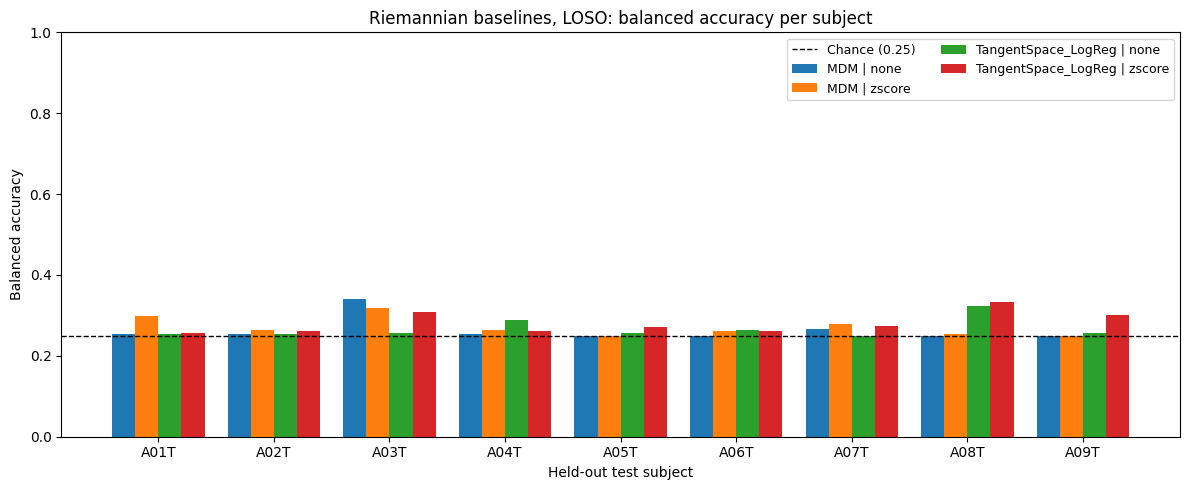

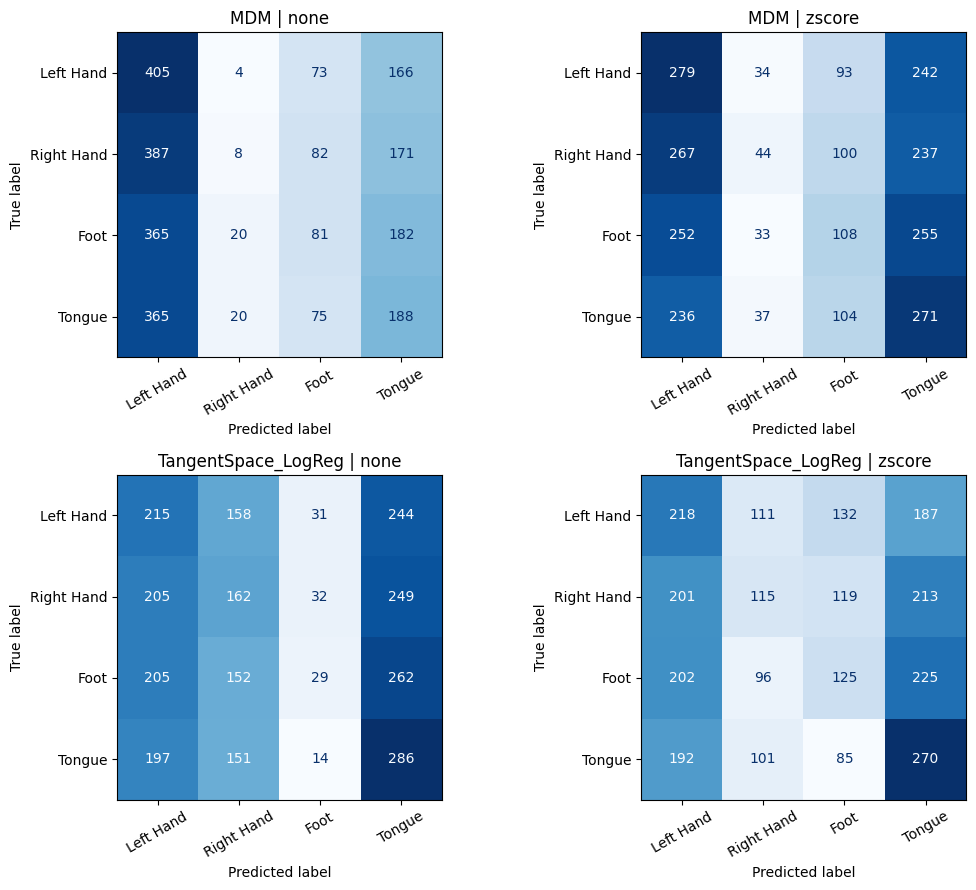

In [9]:
conditions = [(m, n) for m in results_df["Model"].unique() for n in NORMALIZATIONS]
x = np.arange(len(ALL_SUBJECTS))
width = 0.8 / len(conditions)

plt.figure(figsize=(12, 5))
for k, (m, n) in enumerate(conditions):
    vals = per_subject[(m, n)].reindex(ALL_SUBJECTS).values
    plt.bar(x + (k - (len(conditions) - 1) / 2) * width, vals, width, label=f"{m} | {n}")
plt.axhline(0.25, color="k", linestyle="--", linewidth=1, label="Chance (0.25)")
plt.xticks(x, ALL_SUBJECTS)
plt.ylim(0, 1)
plt.ylabel("Balanced accuracy")
plt.xlabel("Held-out test subject")
plt.title("Riemannian baselines, LOSO: balanced accuracy per subject")
plt.legend(ncol=2, fontsize=9)
plt.tight_layout()
plt.savefig("saved_plots/Riemannian_LOSO_BalancedAccuracy.png", dpi=200)
plt.show()

# Pooled confusion matrices (descriptive; the headline numbers remain the per-subject means)
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (m, n) in zip(axes.ravel(), conditions):
    tg, pr = pooled[(m, n)]
    cm = confusion_matrix(tg, pr, labels=LABELS)
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{m} | {n}")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig("saved_plots/Riemannian_LOSO_ConfusionMatrices.png", dpi=200)
plt.show()

## Comparison with the neural networks
Both neural notebooks currently write their LOSO table to the same file name, `loso_results.csv`, so the second one overwrites the first. Rename the outputs, for example:

- EEGNet LOSO table → `loso_results_eegnet.csv`
- AttentionBaseNet LOSO table → `loso_results_attention.csv`

and set the paths below. If a file is missing, it is simply skipped.

How to read the comparison:
- `zscore` Riemannian rows share the neural preprocessing: this is the matched comparison.
- `none` rows compare **complete pipelines** (preprocessing + model), not just architectures.
- Neural models use the validation subject for early stopping, while the Riemannian models have no tuned component. This asymmetry is part of the protocol and should be stated when reporting.
- The Riemannian variant used as the reference below is selected by **mean validation balanced accuracy**, never by test results.

Riemannian reference variant (best mean validation balanced accuracy = 0.286): TangentSpace_LogReg | zscore

=== All systems: mean ± std across 9 test subjects ===


Balanced Accuracy        Macro F1  \
                                                     mean    std     mean   
Family     System                                                           
Neural     AttentionBaseNet | Aug                   0.520  0.122    0.509   
           AttentionBaseNet | NoAug                 0.524  0.114    0.515   
           EEGNet | Aug                             0.540  0.100    0.527   
           EEGNet | NoAug                           0.532  0.093    0.518   
Riemannian MDM | none                               0.263  0.029    0.126   
           MDM | zscore                             0.271  0.024    0.183   
           TangentSpace_LogReg | none               0.267  0.024    0.152   
           TangentSpace_LogReg | zscore             0.281  0.027    0.196   

                                                
                                           std  
Family     System                               
Neural     AttentionBaseNet | Aug        0.126  
           AttentionBaseNet | NoAug      0.112  
           EEGNet | Aug                  0.115  
           EEGNet | NoAug                0.106  
Riemannian MDM | none                    0.049  
           MDM | zscore                  0.064  
           TangentSpace_LogReg | none    0.056  
           TangentSpace_LogReg | zscore  0.037


=== Per-subject balanced accuracy ===


System,AttentionBaseNet | Aug,AttentionBaseNet | NoAug,EEGNet | Aug,EEGNet | NoAug,MDM | none,MDM | zscore,TangentSpace_LogReg | none,TangentSpace_LogReg | zscore
Test Subject,,,,,,,,
A01T,0.587,0.625,0.583,0.542,0.253,0.299,0.253,0.257
A02T,0.375,0.375,0.431,0.448,0.253,0.264,0.253,0.260
A03T,0.625,0.628,0.639,0.628,0.340,0.319,0.257,0.309
A04T,0.476,0.420,0.476,0.458,0.253,0.264,0.288,0.260
A05T,0.299,0.392,0.354,0.399,0.250,0.250,0.257,0.271
A06T,0.493,0.497,0.566,0.562,0.250,0.260,0.264,0.260
A07T,0.531,0.493,0.569,0.490,0.267,0.278,0.250,0.274
A08T,0.642,0.601,0.580,0.573,0.250,0.253,0.323,0.333
A09T,0.649,0.684,0.663,0.691,0.250,0.250,0.257,0.302



=== Paired differences: TangentSpace_LogReg | zscore minus each neural system (exploratory) ===
AttentionBaseNet | Aug              mean delta = -0.239 | Riemannian better in 0/9 subjects | Wilcoxon p = 0.0039
AttentionBaseNet | NoAug            mean delta = -0.243 | Riemannian better in 0/9 subjects | Wilcoxon p = 0.0039
EEGNet | Aug                        mean delta = -0.259 | Riemannian better in 0/9 subjects | Wilcoxon p = 0.0039
EEGNet | NoAug                      mean delta = -0.252 | Riemannian better in 0/9 subjects | Wilcoxon p = 0.0039


C:\Users\ACER\AppData\Local\Temp\ipykernel_11368\2085408162.py:50: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([comp_pivot[s].dropna() for s in order], labels=order, showmeans=True)


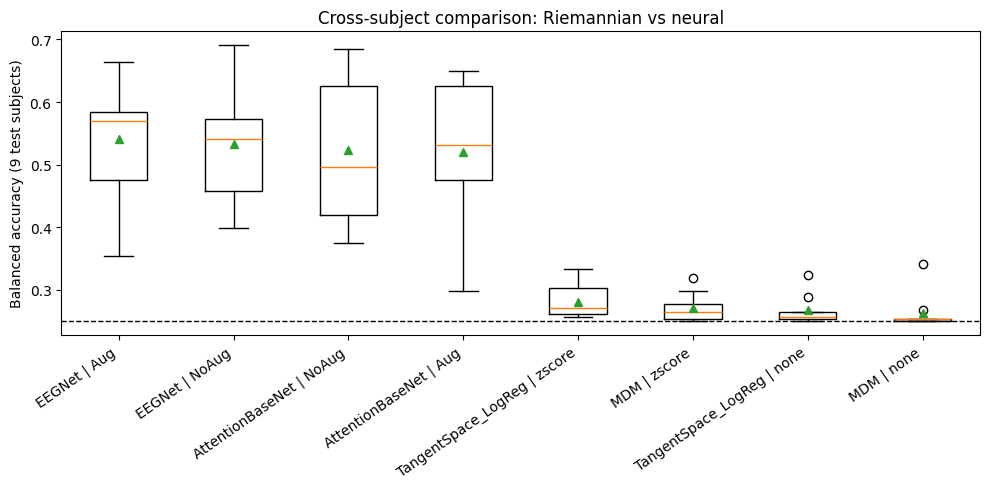

In [10]:
NEURAL_FILES = {
    "EEGNet": "loso_results_notebook_8.csv",
    "AttentionBaseNet": "loso_results_notebook_9.1.csv",
}

# Riemannian reference, chosen on validation subjects only
val_means = results_df.groupby(["Model", "Normalization"])["Val Balanced Accuracy"].mean()
ref_model, ref_norm = val_means.idxmax()
print(f"Riemannian reference variant (best mean validation balanced accuracy = {val_means.max():.3f}): "
      f"{ref_model} | {ref_norm}\n")

tables = []
for _, r in results_df.iterrows():
    tables.append({"System": f"{r['Model']} | {r['Normalization']}", "Family": "Riemannian",
                   "Test Subject": r["Test Subject"],
                   "Balanced Accuracy": r["Balanced Accuracy"], "Macro F1": r["Macro F1"]})

for net_name, path in NEURAL_FILES.items():
    if not os.path.exists(path):
        print(f"[skip] {path} not found ({net_name})")
        continue
    neural_df = pd.read_csv(path)
    for _, r in neural_df.iterrows():
        tables.append({"System": f"{net_name} | {r['Condition']}", "Family": "Neural",
                       "Test Subject": r["Test Subject"],
                       "Balanced Accuracy": r["Balanced Accuracy"], "Macro F1": r["Macro F1"]})

comp = pd.DataFrame(tables)
comp_summary = comp.groupby(["Family", "System"])[["Balanced Accuracy", "Macro F1"]].agg(["mean", "std"]).round(3)
print("=== All systems: mean ± std across 9 test subjects ===")
display(comp_summary)

comp_pivot = comp.pivot(index="Test Subject", columns="System", values="Balanced Accuracy")
print("\n=== Per-subject balanced accuracy ===")
display(comp_pivot.round(3))

ref_system = f"{ref_model} | {ref_norm}"
neural_systems = [s for s in comp_pivot.columns if comp.loc[comp["System"] == s, "Family"].iloc[0] == "Neural"]
if neural_systems:
    print(f"\n=== Paired differences: {ref_system} minus each neural system (exploratory) ===")
    for s in neural_systems:
        d = (comp_pivot[ref_system] - comp_pivot[s]).dropna()
        line = f"{s:35s} mean delta = {d.mean():+.3f} | Riemannian better in {(d > 0).sum()}/{len(d)} subjects"
        if len(d) > 5 and not (d == 0).all():
            line += f" | Wilcoxon p = {wilcoxon(d)[1]:.4f}"
        print(line)

    plt.figure(figsize=(10, 5))
    order = comp_pivot.mean().sort_values(ascending=False).index
    plt.boxplot([comp_pivot[s].dropna() for s in order], labels=order, showmeans=True)
    plt.axhline(0.25, color="k", linestyle="--", linewidth=1)
    plt.xticks(rotation=35, ha="right")
    plt.ylabel("Balanced accuracy (9 test subjects)")
    plt.title("Cross-subject comparison: Riemannian vs neural")
    plt.tight_layout()
    plt.savefig("saved_plots/Riemannian_vs_Neural_LOSO.png", dpi=200)
    plt.show()

## Limitations and reporting notes
- Only 9 subjects: p-values are exploratory and standard deviations across subjects are large in this dataset. Report per-subject results alongside means.
- The Riemannian models use fixed, untuned hyper-parameters; the neural models use validation-based early stopping. Neither side is given a tuning advantage on the test subjects.
- The `none` vs `zscore` comparison is a preprocessing ablation. If one variant is carried forward to a final pipeline, choose it by validation balanced accuracy, as done above, not by test means.
- No augmentation and no test-time adaptation (`tsupdate=False`) are used. Re-estimating the tangent-space reference or recentering covariances on the target subject would be a separate, transductive experiment and should be reported as such.
- Single dataset and single (cross-subject) protocol: the results do not by themselves support general claims about Riemannian versus deep-learning decoding.